<span style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">An Exception was encountered at '<a href="#papermill-error-cell">In [11]</a>'.</span>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
import glob, os, shutil, cv2, json, sys
from tqdm import tqdm
from pathlib import Path

sys.path.append('../..')
from Dataset.index import Normalization, TilesBuilder, getFiles, setFolder, showTile, getDataInfo

In [2]:
BASE_PATH = f'../Dataset/{Path().resolve().name}'
BASE_PATH

'../Dataset/dataset_wu'

In [3]:
def getDAT(path):
    return np.fromfile(path, dtype=np.float32).reshape((128, 128, 128))

OPTIONS = json.loads(open('../../Task/info.json', 'r').read())
OPTIONS['dataset'] = BASE_PATH.split('/')[-1].strip()
OPTIONS

{'network': 'unet_wu_z',
 'dataset': 'dataset_wu',
 'img_size': None,
 'scaling': 'percentile',
 'lr': 0.0001,
 'loss': 'bce_balanced',
 'batch_size': 2,
 'scheduler': 'constant',
 'dropout': 0.0,
 'num_filters': 16,
 'ema': False,
 'epochs': 70,
 'patience': 70,
 'n_trials': 1,
 'trial': 0,
 'augmentations': {'flip': {'axes': [1], 'prob': 0.5},
  'gain': {'factor': [0.5, 1.0]},
  'n_aug': 2}}

In [4]:
with open('../../Task/info.json', 'w', encoding='utf-8') as file:
    json.dump(OPTIONS, file, ensure_ascii=False, indent=4) 

# CONVERTENDO IMAGENS

In [5]:
images = getFiles('original/images')
masks  = getFiles('original/masks')

print(images[0])
print(masks[0])

/home/lamcegrva/Projects/Falhas/Dataset/dataset_wu/original/images/0.dat
/home/lamcegrva/Projects/Falhas/Dataset/dataset_wu/original/masks/0.dat




 showing index 0: 0.dat
-6.9158764 6.4703856


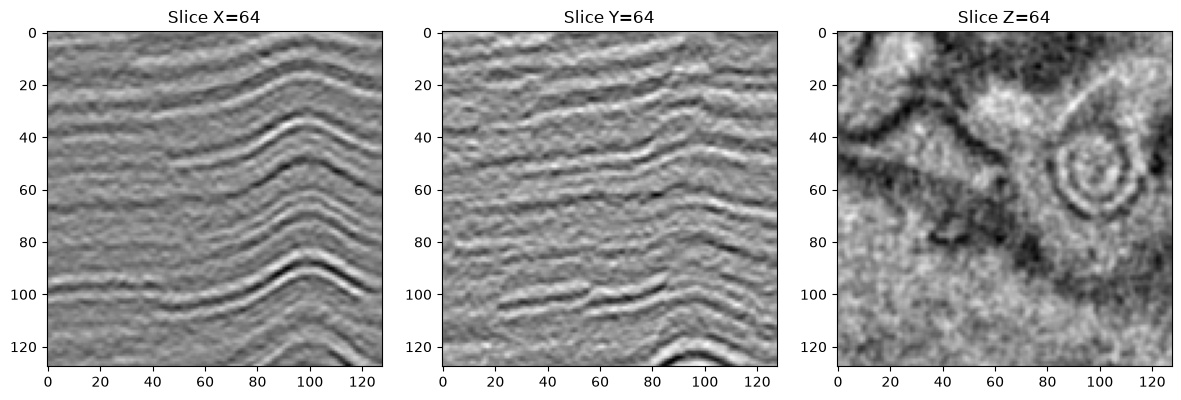

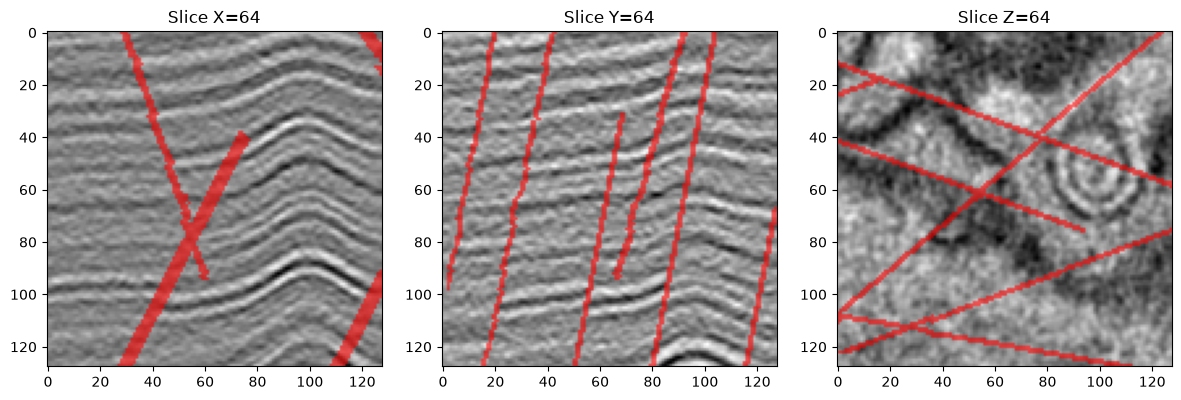



 showing index 1: 1.dat
-3.943627 3.8218153


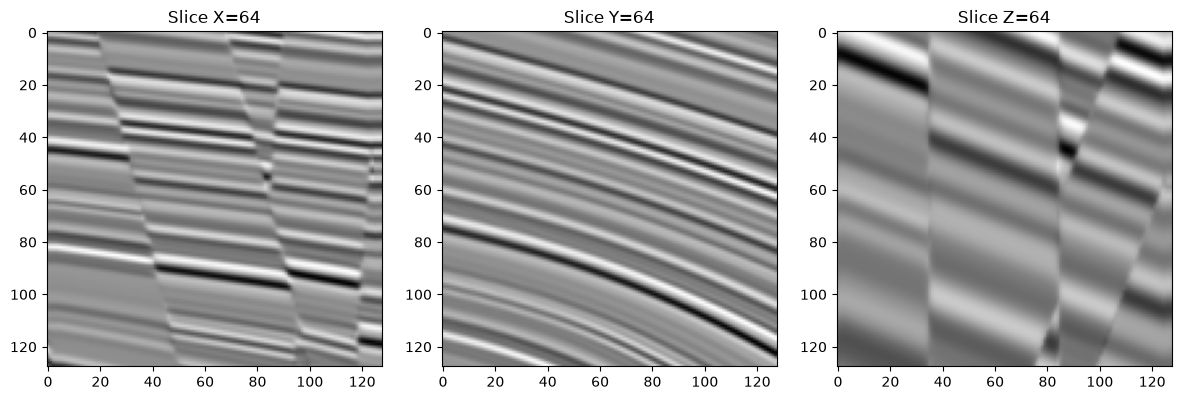

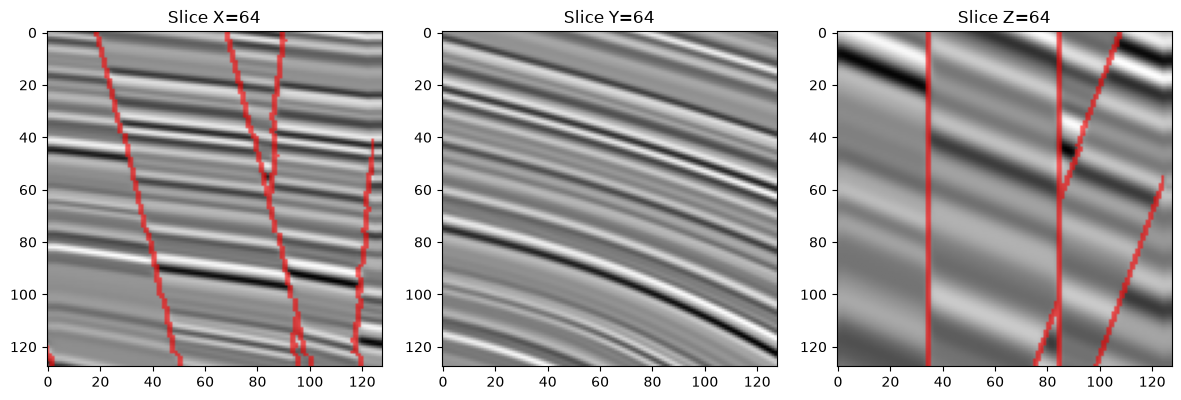



 showing index 2: 10.dat
-5.7198753 4.9404955


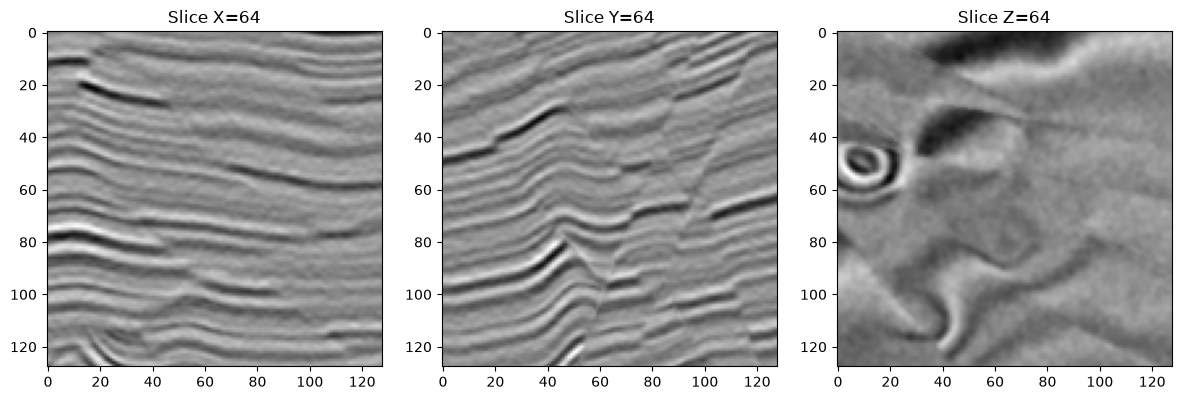

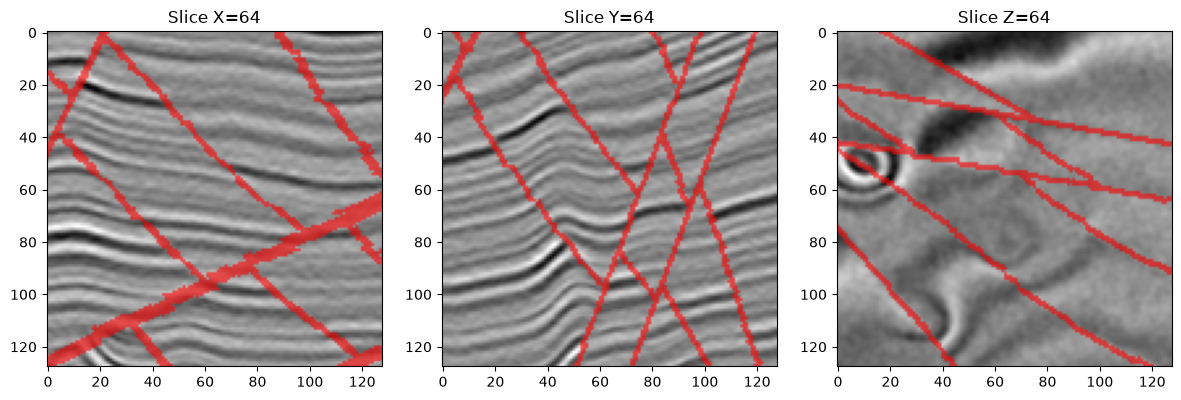



 showing index 3: 100.dat
-6.25327 5.29154


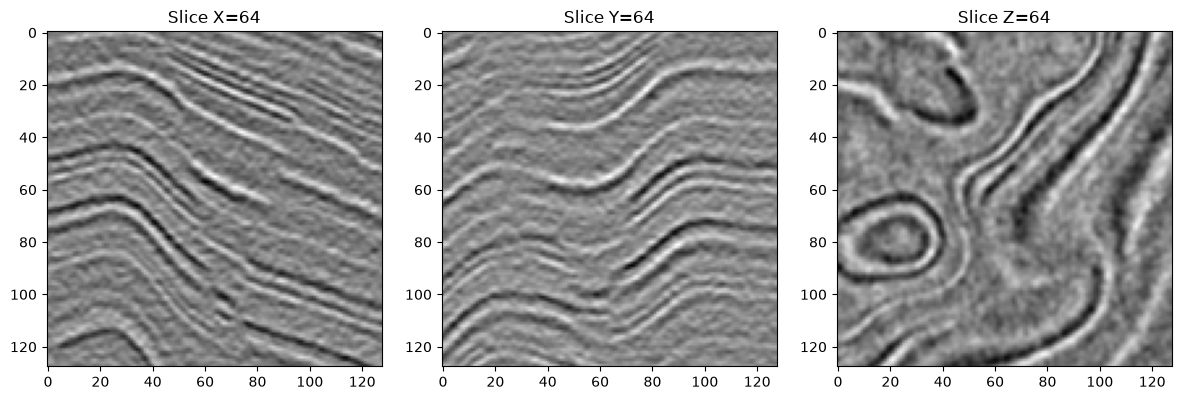

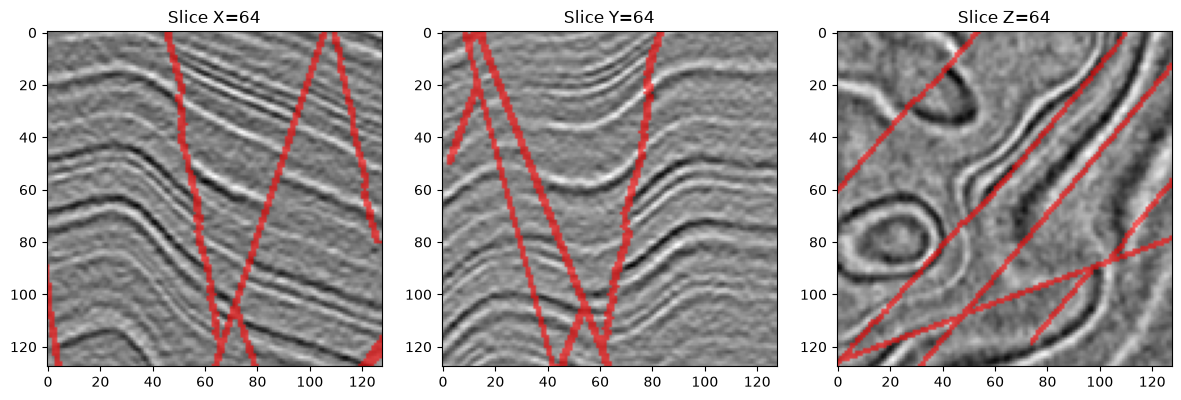



 showing index 4: 101.dat
-6.155443 5.853287


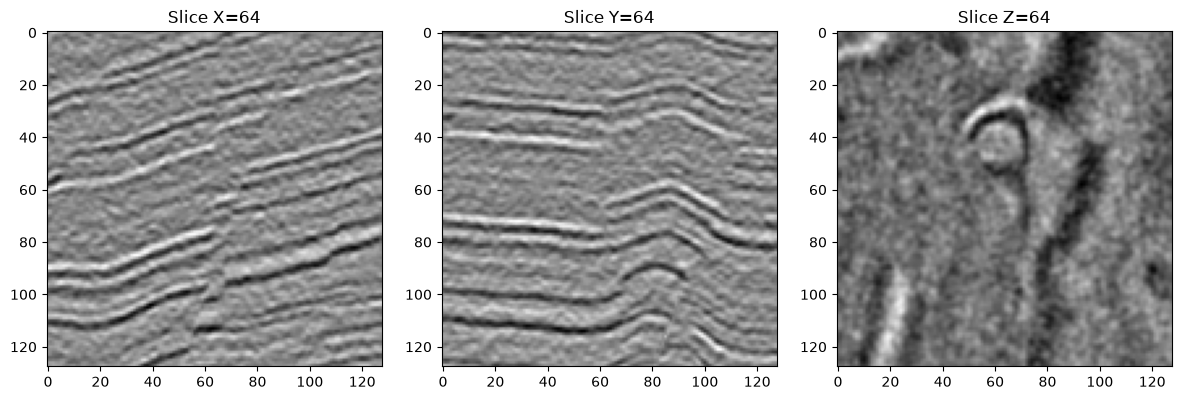

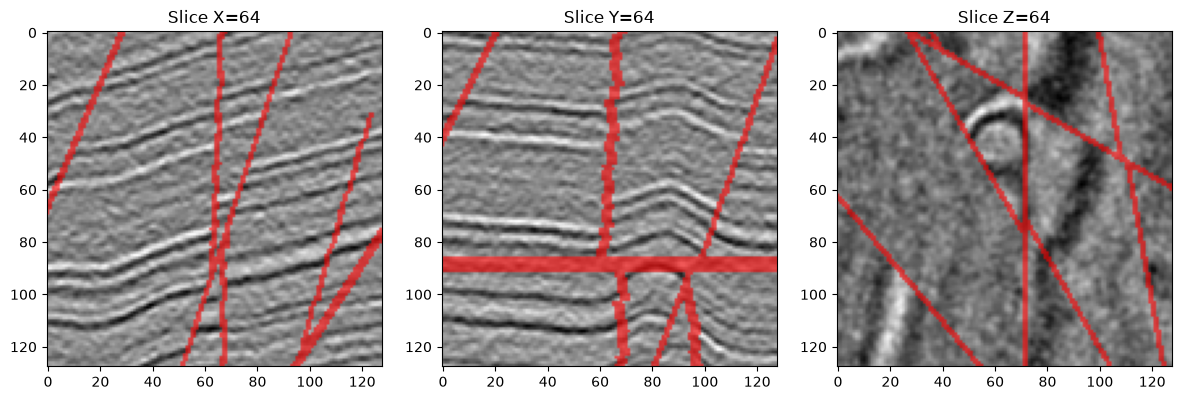



 showing index 5: 102.dat
-5.3385043 4.3343425


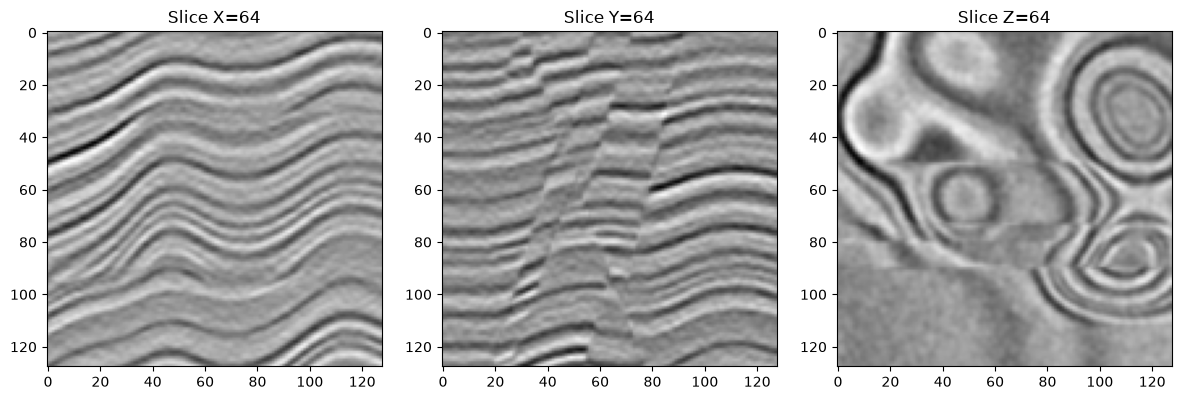

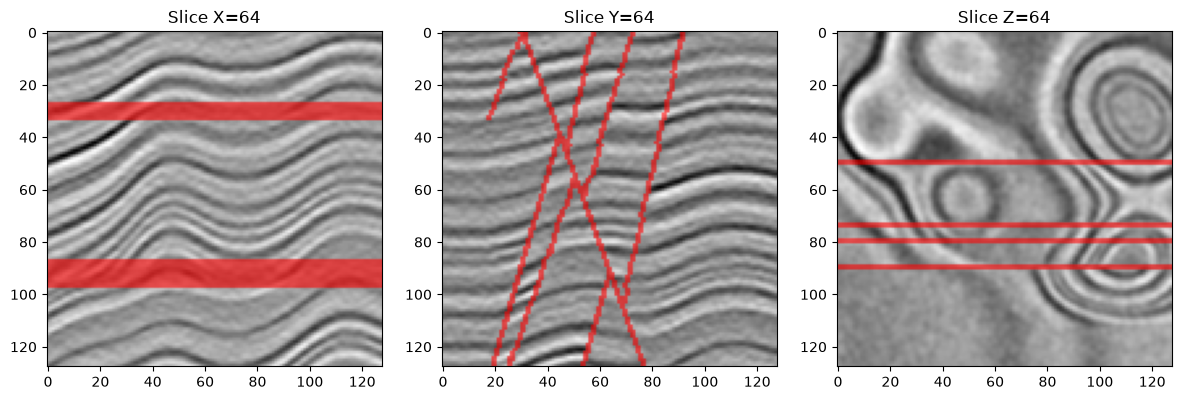

In [6]:
def formatAxis(img):
    return np.transpose(img, (0, 2, 1))

def getImage(base_path, file_name=None):
    path = os.path.join(base_path, file_name) if file_name else base_path
    return formatAxis(getDAT(path))

for i, (img_path, msk_path) in enumerate(zip(images, masks)):
    if i == 6:
        break

    file_name = Path(img_path).name
    print(f'\n\n showing index {i}:', file_name)

    img  = getImage('original/images', file_name)
    mask = getImage('original/masks',  file_name)

    print(img.min(), img.max())
    showTile(img=img)
    showTile(img=img, mask=mask)

### NORMALIZAÇÃO

- `scaling` do `info.json` escolhe o escalonamento da `Normalization` (`Dataset/index.py`); sem a chave é `'normalize'`.
- `'normalize'`: min-max de cada volume para [0, 1].
- `'percentile'`: corte no p01/p99 do conjunto inteiro, reescalado para [0, 1].
- `'standardize'`: padronização de cada volume (média 0, desvio 1), o passo da seção 3.2 do artigo da ResACEUnet.
- `null`: o volume cru, sem escalonamento.
- A escolha vai para a coluna `scaling` do `DataBase.csv`; o `index.py` refaz o `Format` quando a rodada pede outro.

In [7]:
SCALING   = OPTIONS.get('scaling', Normalization.DEFAULT)
normalize = Normalization(SCALING).fit(images, getImage)

setFolder('images')
setFolder('masks')
print(normalize)

Normalization('percentile'): corte no p01/p99 do conjunto (-2.6483394169807433, 2.6927463078498874) para [0, 1]


In [8]:
for img_path, msk_path in tqdm(zip(images, masks), total=len(images)):
    img = getImage('original/images', Path(img_path).name)
    msk = getImage('original/masks',  Path(msk_path).name)

    img = normalize(img)
    file_name = Path(img_path).stem
    
    np.save(os.path.join('images', f'{file_name}.npy'), img)
    np.save(os.path.join('masks',  f'{file_name}.npy'), msk)

  0%|          | 0/220 [00:00<?, ?it/s]

  1%|          | 2/220 [00:00<00:15, 13.75it/s]

  2%|▏         | 4/220 [00:00<00:15, 13.72it/s]

  3%|▎         | 6/220 [00:00<00:15, 13.72it/s]

  4%|▎         | 8/220 [00:00<00:16, 12.51it/s]

  5%|▍         | 10/220 [00:00<00:16, 12.65it/s]

... (102 outputs left out)

 98%|█████████▊| 216/220 [00:16<00:00, 13.03it/s]

 99%|█████████▉| 218/220 [00:16<00:00, 13.02it/s]

100%|██████████| 220/220 [00:16<00:00, 13.02it/s]

100%|██████████| 220/220 [00:16<00:00, 13.02it/s]

In [9]:
df = [] 

for img_path, mask_path in tqdm(zip(getFiles('images'), getFiles('masks'))):
    img  = np.load(img_path)
    mask = np.load(mask_path)
    data = dict()

    data['id'] = Path(img_path).name
    data['img_min']  = np.min(img)
    data['img_max']  = np.max(img)
    data['img_mean'] = np.mean(img)
    data['img_std']  = np.std(img)

    data['msk_min'] = np.min(mask)
    data['msk_max'] = np.max(mask)

    data['shape'] = img.shape
    data['img_path']  = img_path
    data['mask_path'] = mask_path
    data['scaling'] = SCALING
    df.append(data)


df = pd.DataFrame(df)
print(df.img_path.iloc[2])
df

0it [00:00, ?it/s]

21it [00:00, 207.31it/s]

42it [00:00, 205.32it/s]

65it [00:00, 213.47it/s]

88it [00:00, 217.68it/s]

111it [00:00, 220.63it/s]

... (3 outputs left out)

203it [00:00, 223.11it/s]

220it [00:00, 220.50it/s]

/home/lamcegrva/Projects/Falhas/Dataset/dataset_wu/images/10.npy


,id,img_min,img_max,img_mean,img_std,msk_min,msk_max,shape,img_path,mask_path,scaling
0,0.npy,0.0,1.0,0.497236,0.211666,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
1,1.npy,0.0,1.0,0.496481,0.184599,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
2,10.npy,0.0,1.0,0.496158,0.185499,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
3,100.npy,0.0,1.0,0.496550,0.203066,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
4,101.npy,0.0,1.0,0.497008,0.210493,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
...,...,...,...,...,...,...,...,...,...,...,...
215,95.npy,0.0,1.0,0.495437,0.192614,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
216,96.npy,0.0,1.0,0.495381,0.201204,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
217,97.npy,0.0,1.0,0.495210,0.186244,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
218,98.npy,0.0,1.0,0.494706,0.201227,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile


In [10]:
pd.concat([getDataInfo(images, getImage, 'original'), getDataInfo(getFiles('images'), np.load, 'formatado')])

,arquivos,formato,shape,min,max,media,desvio
original,220,.dat float32,"(128, 128, 128)",-7.892282,8.168264,0.000351,1.051695
formatado,220,.npy float32,"(128, 128, 128)",0.000000,1.000000,0.495930,0.191117


<span id="papermill-error-cell" style="color:red; font-family:Helvetica Neue, Helvetica, Arial, sans-serif; font-size:2em;">Execution using papermill encountered an exception here and stopped:</span>

In [11]:
if OPTIONS.get('img_size') is None:
    df.to_csv('DataBase.csv', index=None)
    display(df)
    sys.exit("Finalizando o programa: sem tiles nessa rodada")

,id,img_min,img_max,img_mean,img_std,msk_min,msk_max,shape,img_path,mask_path,scaling
0,0.npy,0.0,1.0,0.497236,0.211666,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
1,1.npy,0.0,1.0,0.496481,0.184599,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
2,10.npy,0.0,1.0,0.496158,0.185499,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
3,100.npy,0.0,1.0,0.496550,0.203066,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
4,101.npy,0.0,1.0,0.497008,0.210493,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
...,...,...,...,...,...,...,...,...,...,...,...
215,95.npy,0.0,1.0,0.495437,0.192614,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
216,96.npy,0.0,1.0,0.495381,0.201204,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
217,97.npy,0.0,1.0,0.495210,0.186244,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile
218,98.npy,0.0,1.0,0.494706,0.201227,0.0,1.0,"(128, 128, 128)",/home/lamcegrva/Projects/Falhas/Dataset/datase...,/home/lamcegrva/Projects/Falhas/Dataset/datase...,percentile


SystemExit: Finalizando o programa: sem tiles nessa rodada

/home/lamcegrva/miniconda3/envs/torch-gpu/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


# TILES

In [ ]:
IMG_SIZE = tuple(OPTIONS['img_size'])
IMG_SIZE

In [ ]:
# os tiles saem de images/ e masks/ (ja normalizados e com os eixos corrigidos), nao dos .dat originais
tileImages = getFiles('images')
tileMasks  = getFiles('masks')

tiles = TilesBuilder(target_size=IMG_SIZE, main_dir='tiles')
for img_path, mask_path in tqdm(zip(tileImages, tileMasks), total=len(tileImages)):
    tiles.update(img_path,  'images/', is_mask=False)
    tiles.update(mask_path, 'masks/',  is_mask=True)

In [ ]:
print(len(getFiles('tiles/images')), 'imagens geradas')

In [ ]:
df = pd.DataFrame()
df['img_path']  = getFiles('tiles/images')
df['mask_path'] = getFiles('tiles/masks')

assert len(df) > 0, 'nenhum tile foi gerado'
assert [Path(p).stem for p in df.img_path] == [Path(p).stem for p in df.mask_path], 'tiles de imagem e mascara desalinhados'

stats = []
for path in tqdm(df.img_path, total=len(df)):
    tile = np.load(path)
    stats.append({
        'shape': tile.shape,
        'min':   np.min(tile),
        'max':   np.max(tile),
        'mean':  np.mean(tile),
        'std':   np.std(tile),
    })

for column in ['shape', 'min', 'max', 'mean', 'std']:
    df[column] = [item[column] for item in stats]

shapes = set(df['shape'])
assert shapes == {IMG_SIZE}, f'tiles com shape inesperado: {shapes} (esperado {IMG_SIZE})'

df['scaling'] = SCALING
print(df.img_path.iloc[0])
df.to_csv('DataBase.csv', index=None)
df